# 6장 · 일반적인 머신러닝 워크플로

6장은 코드보다 **절차**가 중심인 장이에요. 그래서 작은 문제 하나를 정해 놓고
**작업 정의 → 모델 개발 → 배포** 세 단계를 처음부터 끝까지 실제로 밟아 봐요.

> 🎯 **오늘의 가상 프로젝트**: "우편물 분류 공장에서, 손글씨 **0**(특수 우편번호)만 골라내는 검출기를 만들어 주세요."
> → MNIST로 **'0인가 아닌가'** 이진 분류. 양성이 약 10%뿐인 **불균형** 문제라서 6장의 함정이 다 드러나요.

| 단계 | 절 | 이 노트북에서 하는 일 | 그림 노트 카드 · 내 필기 |
|---|---|---|---|
| ① 작업 정의 | §6.1 | 입력 · 출력 정하기, 데이터 이해, **지표 고르기 (정확도의 함정, ROC · AUC)** | 6.1 작업 정의 |
| ② 모델 개발 | §6.2 | 데이터 준비 → 평가 방법 → **기준점 넘기 → 과대적합 → 규제 · 튜닝** | 6.2 모델 개발 순서 |
| ③ 배포 | §6.3 | 임계값 정하기 · 저장 · 다시 불러오기 · 속도 · **개념 이동 감시** | 6.3 모델 배포 |

CPU로 전체 실행 약 3~5분. 🔍 = 내부 들여다보기, 💬 = 설명 포인트.

## 0. 준비

- `KERAS_BACKEND`는 **`import keras` 전에** 정해요. 바꾸려면 커널 재시작 → 이 셀부터 다시.
- 시드를 고정해서 실행할 때마다 거의 같은 결과가 나오게 해요 (CPU 연산 순서 때문에 소수점 끝자리는 조금 달라질 수 있어요).

In [1]:
import os
os.environ["KERAS_BACKEND"] = "jax"   # "tensorflow" / "torch" / "jax"

import numpy as np
import matplotlib.pyplot as plt
import keras
from keras import layers

keras.utils.set_random_seed(42)
plt.rcParams["font.family"] = "Malgun Gothic"     # 그래프 한글 깨짐 방지 (윈도)
plt.rcParams["axes.unicode_minus"] = False
print("keras", keras.__version__, "| backend =", keras.backend.backend())

keras 3.15.1 | backend = jax

In [2]:
def plot_history(histories, key="val_loss", title=None, ylim=None):
    """여러 history를 한 그래프에 겹쳐 그리기. histories = {"이름": history}"""
    plt.figure(figsize=(7, 3.6))
    for name, h in histories.items():
        v = h.history[key]
        plt.plot(range(1, len(v) + 1), v, "-o", ms=3, label=name)
    plt.xlabel("에포크"); plt.ylabel(key); plt.title(title or key)
    if ylim: plt.ylim(*ylim)
    plt.legend(); plt.grid(alpha=.3); plt.show()

# ① 작업 정의 (§6.1)

## 1-1. 문제 정의

| 질문 | 이 프로젝트의 답 |
|---|---|
| 입력은? | 28×28 흑백 손글씨 이미지 |
| 예측할 것은? | 이 숫자가 0인가? (예/아니오) |
| 문제 유형은? | **이진 분류** → 마지막 층 `Dense(1, sigmoid)` + `binary_crossentropy` (4장 정리표) |
| 제약은? | 놓치면(거짓 음성) 우편물이 잘못 배송됨 → **재현율이 중요** |

In [3]:
from keras.datasets import mnist

(x_all, d_all), (x_test, d_test) = mnist.load_data()
y_all = (d_all == 0).astype("float32")       # 0이면 1(양성), 나머지 0
y_test = (d_test == 0).astype("float32")
print("이미지:", x_all.shape, "레이블 예:", d_all[:10], "→", y_all[:10])

이미지: (60000, 28, 28) 레이블 예: [5 0 4 1 9 2 1 3 1 4] → [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]

## 1-2. 데이터 이해 — 모델보다 먼저 데이터를 **본다**

양성(0) 비율 = 0.099  → 10장 중 1장꼴. 불균형!

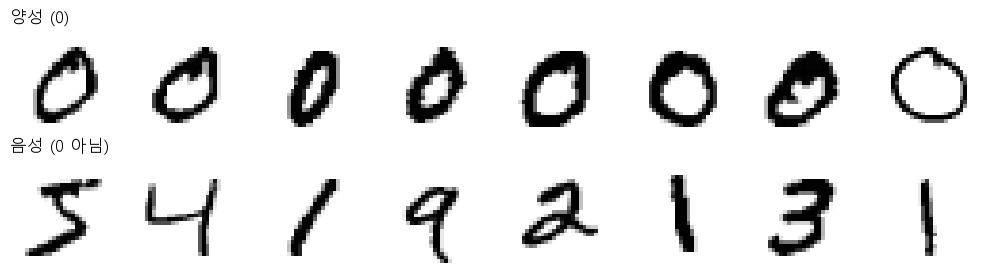

In [4]:
pos_rate = y_all.mean()
print(f"양성(0) 비율 = {pos_rate:.3f}  → 10장 중 1장꼴. 불균형!")

fig, axes = plt.subplots(2, 8, figsize=(10, 2.8))
for ax, img in zip(axes[0], x_all[y_all == 1][:8]): ax.imshow(img, cmap="gray_r"); ax.axis("off")
for ax, img in zip(axes[1], x_all[y_all == 0][:8]): ax.imshow(img, cmap="gray_r"); ax.axis("off")
axes[0, 0].set_title("양성 (0)", loc="left"); axes[1, 0].set_title("음성 (0 아님)", loc="left")
plt.tight_layout(); plt.show()

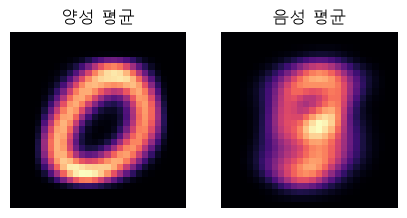

→ 양성 평균이 뚜렷한 고리 모양. 입력에 정답을 맞힐 정보가 '있다'는 신호

In [5]:
# 평균 이미지: 클래스마다 '전형적인 모습'이 다른가?
fig, axes = plt.subplots(1, 2, figsize=(5, 2.6))
axes[0].imshow(x_all[y_all == 1].mean(axis=0), cmap="magma"); axes[0].set_title("양성 평균"); axes[0].axis("off")
axes[1].imshow(x_all[y_all == 0].mean(axis=0), cmap="magma"); axes[1].set_title("음성 평균"); axes[1].axis("off")
plt.show()
print("→ 양성 평균이 뚜렷한 고리 모양. 입력에 정답을 맞힐 정보가 '있다'는 신호")

## 1-3. 성공 지표 고르기 — 정확도의 함정

💬 **설명 포인트**: "정확도 90% 모델"은 좋은 모델일까?

In [6]:
always_no = np.zeros_like(y_test)       # 무조건 '0 아님'이라고 답하는 '모델'
acc = (always_no == y_test).mean()
recall = (always_no[y_test == 1] == 1).mean()
print(f"무조건 '아니오' 정확도 = {acc:.3f}   ← 아무것도 안 했는데 90%!")
print(f"무조건 '아니오' 재현율 = {recall:.3f}   ← 0을 하나도 못 찾음")

무조건 '아니오' 정확도 = 0.902   ← 아무것도 안 했는데 90%!
무조건 '아니오' 재현율 = 0.000   ← 0을 하나도 못 찾음

> 불균형 문제에서 정확도는 **거짓말을 해요**. 그래서 이렇게 봐요.
>
> | 지표 | 뜻 | 이 프로젝트에서 |
> |---|---|---|
> | **정밀도** | 양성이라고 한 것 중 진짜 양성 | 잘못 골라낸 일반 우편물 |
> | **재현율** | 진짜 양성 중 찾아낸 비율 | 놓친 특수 우편물 ← 더 비쌈 |
> | **ROC AUC** | 임계값과 무관한 '구분 능력' | 모델끼리 비교할 때 |

# ② 모델 개발 (§6.2)

## 2-1. 데이터 준비 + 평가 방법 (홀드아웃)

- 섞어서 훈련 / 검증으로 나눠요. 테스트(`x_test`)는 **마지막에 딱 한 번**만 써요.
- 정규화(0~1)와 펴기(784)는 4장 · 5장과 같아요.

In [7]:
def prep(x):
    return x.reshape((len(x), 784)).astype("float32") / 255

idx = np.random.default_rng(0).permutation(len(x_all))
val_idx, tr_idx = idx[:10000], idx[10000:]
x_tr, y_tr = prep(x_all[tr_idx]), y_all[tr_idx]
x_val, y_val = prep(x_all[val_idx]), y_all[val_idx]
x_te = prep(x_test)
print("훈련", x_tr.shape, f"양성 {y_tr.mean():.3f}", "| 검증", x_val.shape, f"양성 {y_val.mean():.3f}")
print("→ 두 세트의 양성 비율이 비슷해야 검증이 '대표성'을 가짐")

훈련 (50000, 784) 양성 0.099 | 검증 (10000, 784) 양성 0.100
→ 두 세트의 양성 비율이 비슷해야 검증이 '대표성'을 가짐

## 2-2. 상식 수준의 기준점 넘기

가장 단순한 모델(로지스틱 회귀 = `Dense(1, sigmoid)` 하나)부터 시작해요.
지표는 처음부터 **정밀도 · 재현율 · AUC**를 같이 달아요.

In [8]:
def compile_(m):
    # 지표 객체는 상태(누적 카운트)를 가지므로 모델마다 새로 만들어요
    m.compile(optimizer="rmsprop", loss="binary_crossentropy",
              metrics=["accuracy", keras.metrics.Precision(name="precision"),
                       keras.metrics.Recall(name="recall"), keras.metrics.AUC(name="auc")])
    return m

def show(h, tag):
    last = {k: round(v[-1], 4) for k, v in h.history.items() if k.startswith("val_")}
    print(tag, last)

baseline = compile_(keras.Sequential([keras.Input(shape=(784,)), layers.Dense(1, activation="sigmoid")]))
h_base = baseline.fit(x_tr, y_tr, epochs=5, batch_size=256, validation_data=(x_val, y_val), verbose=0)
show(h_base, "기준 모델")

기준 모델 {'val_accuracy': 0.9904, 'val_auc': 0.995, 'val_loss': 0.032, 'val_precision': 0.9499, 'val_recall': 0.9538}

## 2-3. 과대적합할 수 있는 모델로 키우기

층을 넓고 깊게, 에포크를 길게 → 검증 손실이 **바닥을 찍고 오르는** 지점을 찾아요. 그게 용량의 경계예요.

큰 모델 {'val_accuracy': 0.9983, 'val_auc': 0.9999, 'val_loss': 0.0052, 'val_precision': 0.991, 'val_recall': 0.992}
큰 모델 최저 val_loss 에포크: 13

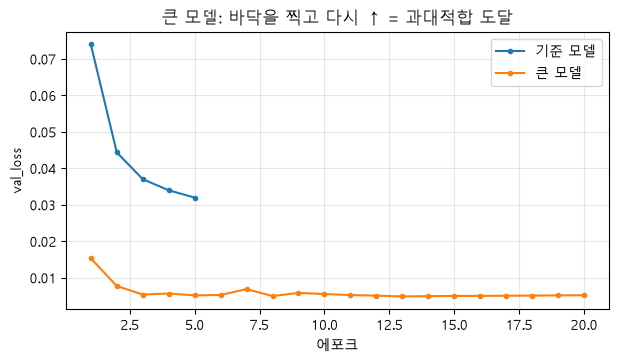

In [9]:
big = compile_(keras.Sequential([keras.Input(shape=(784,)),
                                 layers.Dense(512, activation="relu"),
                                 layers.Dense(512, activation="relu"),
                                 layers.Dense(1, activation="sigmoid")]))
h_big = big.fit(x_tr, y_tr, epochs=20, batch_size=256, validation_data=(x_val, y_val), verbose=0)
show(h_big, "큰 모델")
plot_history({"기준 모델": h_base, "큰 모델": h_big}, key="val_loss", title="큰 모델: 바닥을 찍고 다시 ↑ = 과대적합 도달")
best = int(np.argmin(h_big.history["val_loss"])) + 1
print("큰 모델 최저 val_loss 에포크:", best)

## 2-4. 규제 + 하이퍼파라미터 튜닝

작은 탐색(유닛 수 × 드롭아웃)을 돌려 **검증 AUC**로 고르고, 최저 손실 시점에서 멈추게 `EarlyStopping`을 써요.

⚠️ 탐색을 너무 많이 돌리면 **검증 세트에 과대적합**해요 (5장 정보 누설). 그래서 테스트는 여전히 손대지 않아요.

In [10]:
results = []
for units in (64, 256):
    for rate in (0.0, 0.3):
        m = keras.Sequential([keras.Input(shape=(784,)), layers.Dense(units, activation="relu"),
                              layers.Dropout(rate), layers.Dense(units, activation="relu"),
                              layers.Dropout(rate), layers.Dense(1, activation="sigmoid")])
        compile_(m)
        es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
        m.fit(x_tr, y_tr, epochs=20, batch_size=256, validation_data=(x_val, y_val), callbacks=[es], verbose=0)
        r = m.evaluate(x_val, y_val, verbose=0, return_dict=True)
        results.append((r["auc"], r["recall"], r["precision"], units, rate, m))
        print(f"units={units:3d} dropout={rate:.1f} → val AUC {r['auc']:.4f} recall {r['recall']:.4f} precision {r['precision']:.4f}")

results.sort(key=lambda t: -t[0])
_, _, _, units, rate, final_model = results[0]
print(f"\n선택: units={units}, dropout={rate}")

units= 64 dropout=0.0 → val AUC 0.9999 recall 0.9910 precision 0.9900
units= 64 dropout=0.3 → val AUC 0.9999 recall 0.9839 precision 0.9919
units=256 dropout=0.0 → val AUC 0.9999 recall 0.9910 precision 0.9860
units=256 dropout=0.3 → val AUC 0.9999 recall 0.9930 precision 0.9930

선택: units=64, dropout=0.0

## 2-5. 🔍 ROC 곡선을 직접 그려 보기

`AUC` 지표가 숫자 하나로 요약한 걸, 임계값을 바꿔 가며 직접 계산해서 그려요.
x = **거짓 양성 비율**(FPR), y = **진짜 양성 비율**(TPR = 재현율).

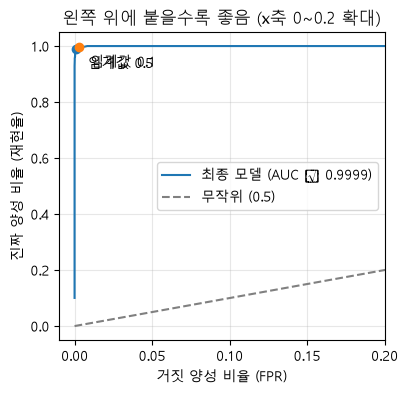

In [11]:
p_val = final_model.predict(x_val, verbose=0).ravel()

thresholds = np.linspace(1, 0, 201)
tpr = [((p_val >= t) & (y_val == 1)).sum() / (y_val == 1).sum() for t in thresholds]
fpr = [((p_val >= t) & (y_val == 0)).sum() / (y_val == 0).sum() for t in thresholds]
auc_manual = np.trapezoid(tpr, fpr)

plt.figure(figsize=(4.2, 4))
plt.plot(fpr, tpr, label=f"최종 모델 (AUC ≈ {auc_manual:.4f})")
plt.plot([0, 1], [0, 1], "--", c="gray", label="무작위 (0.5)")
for t in (0.5, 0.1):
    i = int(np.argmin(np.abs(thresholds - t)))
    plt.scatter(fpr[i], tpr[i], zorder=3); plt.annotate(f"임계값 {t}", (fpr[i], tpr[i]), xytext=(8, -14), textcoords="offset points")
plt.xlabel("거짓 양성 비율 (FPR)"); plt.ylabel("진짜 양성 비율 (재현율)")
plt.xlim(-0.01, 0.2); plt.title("왼쪽 위에 붙을수록 좋음 (x축 0~0.2 확대)"); plt.legend(); plt.grid(alpha=.3); plt.show()

## 2-6. 테스트는 마지막에 딱 한 번

In [12]:
r = final_model.evaluate(x_te, y_test, verbose=0, return_dict=True)
print({k: round(v, 4) for k, v in r.items()})

{'accuracy': 0.9975, 'auc': 0.9968, 'loss': 0.0107, 'precision': 0.9908, 'recall': 0.9837}

# ③ 배포 (§6.3)

## 3-1. 기대치 설정 — 숫자를 고객 언어로 번역

"정확도 99.x%" 대신 **"우편물 1만 통 중 0이 약 1천 통 있을 때, 몇 통 놓치고 몇 통 잘못 골라내는지"**로 말해요.
그리고 **임계값**을 고객과 같이 정해요 (놓치는 비용 vs 잘못 고르는 비용).

In [13]:
p_te = final_model.predict(x_te, verbose=0).ravel()
print("임계값 | 놓친 0 (FN) | 잘못 고른 우편물 (FP) | 재현율  | 정밀도")
for t in (0.9, 0.5, 0.2, 0.05):
    pred = p_te >= t
    tp = (pred & (y_test == 1)).sum(); fn = (~pred & (y_test == 1)).sum(); fp = (pred & (y_test == 0)).sum()
    print(f"  {t:4.2f} | {fn:10d} | {fp:20d} | {tp/(tp+fn):.4f} | {tp/max(tp+fp,1):.4f}")
print("→ 임계값을 낮출수록 덜 놓치지만 잘못 고르는 게 늘어남. 어디에 둘지는 '비용'이 정함")

임계값 | 놓친 0 (FN) | 잘못 고른 우편물 (FP) | 재현율  | 정밀도
  0.90 |         31 |                    3 | 0.9684 | 0.9968
  0.50 |         16 |                    9 | 0.9837 | 0.9908
  0.20 |         12 |                   17 | 0.9878 | 0.9827
  0.05 |         10 |                   27 | 0.9898 | 0.9729
→ 임계값을 낮출수록 덜 놓치지만 잘못 고르는 게 늘어남. 어디에 둘지는 '비용'이 정함

## 3-2. 모델 저장 → 다시 불러오기 (추론 서버가 하는 일)

`.keras` 파일 하나에 **구조 + 가중치 + 컴파일 설정**이 다 들어가요.

In [14]:
import tempfile, time
path = os.path.join(tempfile.gettempdir(), "zero_detector.keras")
final_model.save(path)
print("파일 크기:", round(os.path.getsize(path) / 1024), "KB")

served = keras.models.load_model(path)
same = np.allclose(served.predict(x_te[:100], verbose=0), final_model.predict(x_te[:100], verbose=0))
print("불러온 모델 예측이 원래와 같은가?", same)

파일 크기: 453 KB
불러온 모델 예측이 원래와 같은가? True

In [15]:
# 🔍 추론 속도: 한 장씩 vs 배치로 (서버 · 기기 배치를 고를 때 보는 숫자)
one = x_te[:1]
served.predict(one, verbose=0)                     # 워밍업 (첫 호출은 컴파일 때문에 느림)
t0 = time.perf_counter()
for _ in range(50): served.predict(one, verbose=0)
t_one = (time.perf_counter() - t0) / 50
t0 = time.perf_counter(); served.predict(x_te, batch_size=1024, verbose=0); t_batch = (time.perf_counter() - t0) / len(x_te)
print(f"한 장씩 predict(): {t_one*1000:.2f} ms/장   |   배치 predict(): {t_batch*1000:.4f} ms/장")
print("→ 한 장씩은 호출 오버헤드가 큼. 서버는 요청을 모아 배치로 처리하기도 함")
print("파라미터 수:", served.count_params(), "→ float32면 약", round(served.count_params() * 4 / 1024), "KB, int8 양자화면 약 1/4")

한 장씩 predict(): 9.56 ms/장   |   배치 predict(): 0.0547 ms/장
→ 한 장씩은 호출 오버헤드가 큼. 서버는 요청을 모아 배치로 처리하기도 함
파라미터 수: 54465 → float32면 약 213 KB, int8 양자화면 약 1/4

## 3-3. 모니터링 · 유지 관리 — 개념 이동(concept drift)

배포하고 몇 달 뒤, 공장에 **새 스캐너**가 들어와서 이미지가 조금 흐리고 어긋나게 들어온다고 해 봐요.
모델은 그대로인데 입력 분포가 바뀌면 성능이 **조용히** 떨어져요.

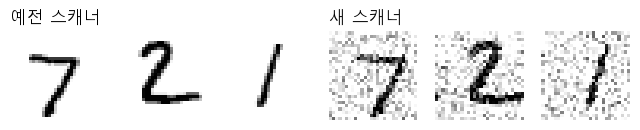

예전 입력    recall 0.9837  precision 0.9908  auc 0.9968
새 스캐너 입력 recall 0.0000  precision 0.0000  auc 0.5115

In [16]:
def new_scanner(x, shift=3, noise=0.25, seed=0):
    imgs = x.reshape(-1, 28, 28)
    imgs = np.roll(imgs, shift, axis=2)                                 # 오른쪽으로 밀림
    imgs = imgs + np.random.default_rng(seed).normal(0, noise, imgs.shape)  # 잡음
    return np.clip(imgs, 0, 1).reshape(-1, 784).astype("float32")

x_drift = new_scanner(x_te)
fig, axes = plt.subplots(1, 6, figsize=(8, 1.6))
for i, ax in enumerate(axes):
    ax.imshow((x_te if i < 3 else x_drift)[i % 3].reshape(28, 28), cmap="gray_r"); ax.axis("off")
axes[0].set_title("예전 스캐너", loc="left"); axes[3].set_title("새 스캐너", loc="left"); plt.show()

for name, x in [("예전 입력", x_te), ("새 스캐너 입력", x_drift)]:
    r = served.evaluate(x, y_test, verbose=0, return_dict=True)
    print(f"{name:8s} recall {r['recall']:.4f}  precision {r['precision']:.4f}  auc {r['auc']:.4f}")

### 🔍 레이블 없이도 이상을 눈치채는 법: 입력 · 출력 통계 감시

배포 환경에선 정답 레이블이 바로 안 들어와요. 대신 **입력 픽셀 통계**와 **예측 양성 비율**을 매일 기록해 두면, 갑자기 변할 때 알람을 걸 수 있어요.

In [17]:
for name, x in [("예전", x_te), ("새 스캐너", x_drift)]:
    p = served.predict(x, verbose=0).ravel()
    print(f"{name:5s} 픽셀 평균 {x.mean():.3f} | 픽셀 표준편차 {x.std():.3f} | 예측 양성 비율 {(p >= 0.5).mean():.3f}")
print("→ 숫자가 달라졌다 = 새 데이터를 모아 레이블을 달고 재훈련할 때 (워크플로 ①로 돌아감)")

예전    픽셀 평균 0.133 | 픽셀 표준편차 0.310 | 예측 양성 비율 0.097
새 스캐너 픽셀 평균 0.206 | 픽셀 표준편차 0.295 | 예측 양성 비율 0.000
→ 숫자가 달라졌다 = 새 데이터를 모아 레이블을 달고 재훈련할 때 (워크플로 ①로 돌아감)

---
## 정리 · 스스로 설명해 보기

1. 이 프로젝트에서 정확도가 나쁜 지표인 이유는? → ______
2. ROC 곡선의 x축 · y축, 그리고 AUC 0.5의 뜻은? → ______
3. 모델 개발 순서를 5단계로 (그림 노트 6.2 카드 보며) → ______
4. 임계값은 누가 어떻게 정하나? → ______
5. 개념 이동을 레이블 없이 눈치채는 방법은? → ______